# Bài 4 — Câu 7: Cây entropy

**Sinh viên:** Nguyễn Đức Vinh — **MSSV:** 6451071087

Dữ liệu theo `TaiLieuLab02.pdf`. Mỗi notebook chạy độc lập.

Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087
Kích thước dữ liệu Wine: (1599, 12)
Dữ liệu thuộc tính: (1599, 11)  | Nhãn: (1599,)
Phân bố nhãn:
quality
5    681
6    638
7    199
4     53
8     18
3     10
Cột phân loại: []
Dạng sau One-Hot Encoding: (1599, 11)
 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8
Train: (1119, 11) Test: (480, 11)
Cây theo information gain (entropy) - cách triển khai trong sklearn; không phải ID3 đa nhánh thuần túy.
Acc

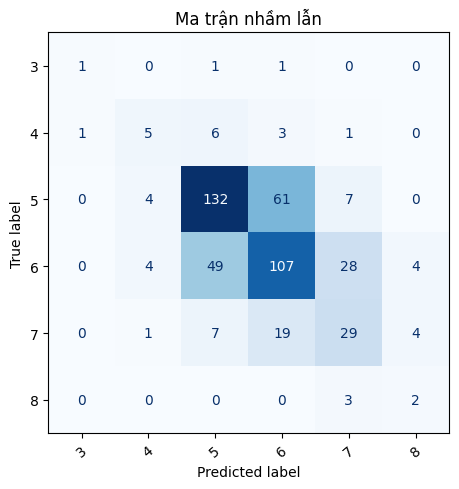

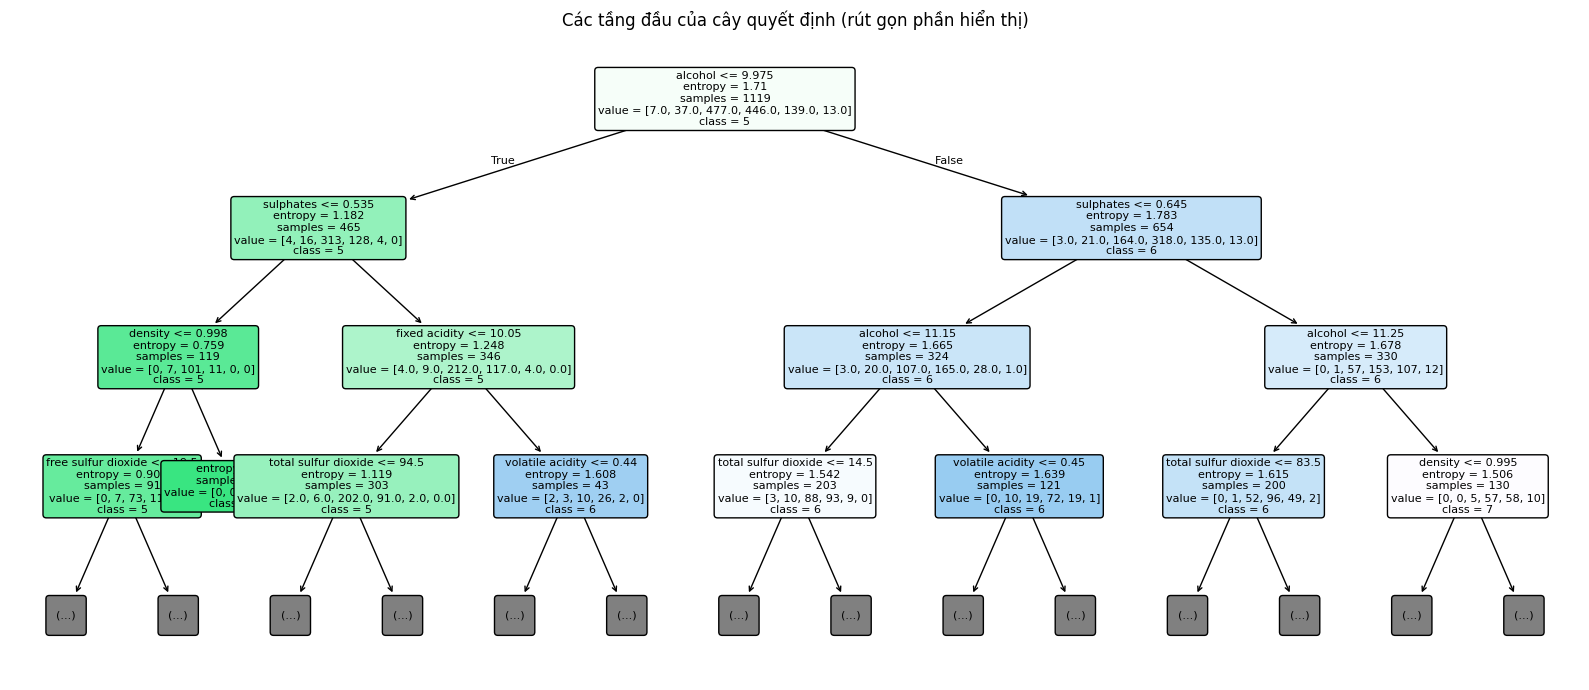

In [1]:
print("Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# Khi chạy trên Colab, nếu chưa có file trong thư mục hiện tại, tự tải từ Drive công khai.
DATA_DIR = Path('data') if Path('data').exists() else Path('.')
DRIVE_IDS = {
    'adult.data.csv': '1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB',
    'adult.test.csv': '1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD',
    'winequality-red.csv': '1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH',
    'heart.csv': '10N9jGzMn-MagDWXORdP-qIpwC3omZJHb',
    'mushrooms.csv': '11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW',
    'test_image_Bai7.jpg': '1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx'
}
def get_file(filename):
    p = DATA_DIR / filename
    if not p.exists():
        import subprocess, sys
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'gdown'])
            import gdown
        gdown.download(id=DRIVE_IDS[filename], output=str(p), quiet=False)
    if not p.exists():
        raise FileNotFoundError('Không tải được ' + filename + '. Hãy tải từ Drive và upload lên Colab.')
    return p

DATASET = 'wine'
data = pd.read_csv(get_file('winequality-red.csv'))
data = data.replace(r'^\s*\?\s*$', np.nan, regex=True).dropna().reset_index(drop=True)
print('Kích thước dữ liệu Wine:', data.shape)

features = data.drop(columns=['quality'])
labels = data['quality']
print('Dữ liệu thuộc tính:', features.shape, ' | Nhãn:', labels.shape)
print('Phân bố nhãn:')
print(labels.value_counts().to_string())
cat_cols = features.select_dtypes(include=['object', 'category']).columns.tolist()
features_encoded = pd.get_dummies(features, columns=cat_cols, dtype=int)
print('Cột phân loại:', cat_cols)
print('Dạng sau One-Hot Encoding:', features_encoded.shape)
print(features_encoded.head(3).to_string(index=False, max_cols=12))
X_train, X_test, y_train, y_test = train_test_split(
    features_encoded, labels, test_size=0.30, random_state=42, stratify=labels)
print('Train:', X_train.shape, 'Test:', X_test.shape)
model = DecisionTreeClassifier(criterion='entropy', random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Cây theo information gain (entropy) - cách triển khai trong sklearn; không phải ID3 đa nhánh thuần túy.')
print('Accuracy:', round(accuracy_score(y_test, pred), 4))
print('Precision (macro):', round(precision_score(y_test, pred, average='macro', zero_division=0), 4))
print('Recall (macro):', round(recall_score(y_test, pred, average='macro', zero_division=0), 4))
print('F1-score (macro):', round(f1_score(y_test, pred, average='macro', zero_division=0), 4))
print(classification_report(y_test, pred, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues', colorbar=False, xticks_rotation=40)
plt.title('Ma trận nhầm lẫn')
plt.tight_layout(); plt.show()
# Chỉ biểu diễn 3 mức đầu để cây lớn vẫn đọc được; mô hình vẫn huấn luyện đủ chiều sâu.
plt.figure(figsize=(16, 7))
plot_tree(model, feature_names=X_train.columns.tolist(), class_names=[str(x) for x in model.classes_],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Các tầng đầu của cây quyết định (rút gọn phần hiển thị)')
plt.tight_layout(); plt.show()
